En este fichero realizaremos un modelo de regresión para determinar el número de bicicletas que se alquilan en Seúl.

In [65]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [66]:
%%R
lib_loc <- "lib_loc"

In [67]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [68]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))



if (!require("psych")) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr")) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc")) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("GGally")) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot")) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)
if (!require("survey", lib.loc = lib_loc)) install.packages("survey", lib = lib_loc)
library(survey, lib.loc = lib_loc)
if (!require("mitools", lib.loc = lib_loc)) install.packages("mitools", lib = lib_loc)
library(mitools, lib.loc = lib_loc)
if (!require("relaimpo", lib.loc = lib_loc)) install.packages("relaimpo", lib = lib_loc)
library(relaimpo, lib.loc = lib_loc)
if (!require("FSelectorRcpp", lib.loc = lib_loc)) install.packages("FSelectorRcpp", lib = lib_loc)
library(FSelectorRcpp, lib.loc = lib_loc)
if (!require("ranger", lib.loc = lib_loc)) install.packages("ranger", lib = lib_loc)
library(ranger, lib.loc = lib_loc)
if (!require("Boruta", lib.loc = lib_loc)) install.packages("Boruta", lib = lib_loc)
library(Boruta, lib.loc = lib_loc)
if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)

if (!require("ggsci", lib.loc = lib_loc)) install.packages("ggsci", lib = lib_loc)
library(ggsci, lib.loc = lib_loc)
if (!require("dendextend", lib.loc = lib_loc)) install.packages("dendextend", lib = lib_loc)
library(dendextend, lib.loc = lib_loc)
if (!require("factoextra", lib.loc = lib_loc)) install.packages("factoextra", lib = lib_loc)
library(factoextra, lib.loc = lib_loc)
if (!require("FactoMineR", lib.loc = lib_loc)) install.packages("FactoMineR", lib = lib_loc)
library(FactoMineR, lib.loc = lib_loc)
if (!require("nFactors", lib.loc = lib_loc)) install.packages("nFactors", lib = lib_loc)
library(nFactors, lib.loc = lib_loc)


if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}


# Carga del fichero

In [69]:
%%R

dfMedidas <- read.csv("SeoulBikeData.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [70]:
%%R
head(dfMedidas, 5)

        Date Rented_Bike_Count Hour Temperature Humidity Wind_speed Visibility
1 01/12/2017               254    0        -5.2       37        2.2       2000
2 01/12/2017               204    1        -5.5       38        0.8       2000
3 01/12/2017               173    2        -6.0       39        1.0       2000
4 01/12/2017               107    3        -6.2       40        0.9       2000
5 01/12/2017                78    4        -6.0       36        2.3       2000
  Dew_point_temperature Solar_Radiation Rainfall Snowfall Seasons    Holiday
1                 -17.6               0        0        0  Winter No Holiday
2                 -17.6               0        0        0  Winter No Holiday
3                 -17.7               0        0        0  Winter No Holiday
4                 -17.6               0        0        0  Winter No Holiday
5                 -18.6               0        0        0  Winter No Holiday
  Functioning Day
1             Yes
2             Yes
3         

Analizamos los tipos de variables

In [71]:
%%R
str(dfMedidas)

'data.frame':	8760 obs. of  14 variables:
 $ Date                 : Factor w/ 365 levels "01/01/2018","01/02/2018",..: 12 12 12 12 12 12 12 12 12 12 ...
 $ Rented_Bike_Count    : int  254 204 173 107 78 100 181 460 930 490 ...
 $ Hour                 : int  0 1 2 3 4 5 6 7 8 9 ...
 $ Temperature          : num  -5.2 -5.5 -6 -6.2 -6 -6.4 -6.6 -7.4 -7.6 -6.5 ...
 $ Humidity             : int  37 38 39 40 36 37 35 38 37 27 ...
 $ Wind_speed           : num  2.2 0.8 1 0.9 2.3 1.5 1.3 0.9 1.1 0.5 ...
 $ Visibility           : int  2000 2000 2000 2000 2000 2000 2000 2000 2000 1928 ...
 $ Dew_point_temperature: num  -17.6 -17.6 -17.7 -17.6 -18.6 -18.7 -19.5 -19.3 -19.8 -22.4 ...
 $ Solar_Radiation      : num  0 0 0 0 0 0 0 0 0.01 0.23 ...
 $ Rainfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Snowfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Seasons              : Factor w/ 4 levels "Autumn","Spring",..: 4 4 4 4 4 4 4 4 4 4 ...
 $ Holiday              : Factor w/ 2 levels "Holiday","N

# EDA

Como podemos observar hay un total de 8760 instancias con 14 variables.
Estas variables se pueden dividir en categóricas y numéricas:

1)   Categóricas:
  * Seasons: Estación del año
  * Date: Fecha
  * Holiday: Periodo de vacaciones, binario
  * Functioning Day: Día laboral, binaria

2)   Numéricas:
  * Rented Bike Count (Variable objetivo): Número de bicicletas alquiladas por cada hora
  * Temperature: Temperatura
  * Humidity: Humedad
  * Wind Speed: Velocidad del viento
  * Visibility: Visibilidad medida en decenas de metros
  * Dew Point Temperature: Temperatura del punto de rocío
  * Solar Radiation: Radiación solar medido en MJ/m2
  * Rainfall: mm de lluvia
  * Snowfall: cm de nieve
  * Hour: Hora


  Hay que destacar que los valores de las variables categóricas Holiday y Functioning Day son binarios, por lo que más adelante se cambiarán a 1s y 0s.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [72]:
%%R
describe(dfMedidas)

                      vars    n    mean     sd  median trimmed    mad   min
Date*                    1 8760  183.00 105.37  183.00  183.00 134.92   1.0
Rented_Bike_Count        2 8760  704.60 645.00  504.50  612.58 553.75   0.0
Hour                     3 8760   11.50   6.92   11.50   11.50   8.90   0.0
Temperature              4 8760   12.88  11.94   13.70   13.19  13.94 -17.8
Humidity                 5 8760   58.23  20.36   57.00   58.02  23.72   0.0
Wind_speed               6 8760    1.72   1.04    1.50    1.63   1.04   0.0
Visibility               7 8760 1436.83 608.30 1698.00 1509.50 447.75  27.0
Dew_point_temperature    8 8760    4.07  13.06    5.10    4.76  14.38 -30.6
Solar_Radiation          9 8760    0.57   0.87    0.01    0.38   0.01   0.0
Rainfall                10 8760    0.15   1.13    0.00    0.00   0.00   0.0
Snowfall                11 8760    0.08   0.44    0.00    0.00   0.00   0.0
Seasons*                12 8760    2.50   1.11    2.00    2.49   1.48   1.0
Holiday*    

Como podemos ver que no hay valores faltantes ni constantes, la cardinalidad máxima dentro de las variables categóricas es de 4, sin embargo, una columna que podemos considerar irrelevante es la fecha, pues tampoco aporta más información que el momento del año en que se ha tomado, información que se puede obtener también de la variable Seasons, además, cada valor de esta variable cambia, no se repite ninguno, por lo que la eliminaremos

In [73]:
%%R

dfMedidas <- read.csv("SeoulBikeData.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


In [74]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("Date")]

In [75]:
%%R
describe(dfMedidas)

                      vars    n    mean     sd  median trimmed    mad   min
Rented_Bike_Count        1 8760  704.60 645.00  504.50  612.58 553.75   0.0
Hour                     2 8760   11.50   6.92   11.50   11.50   8.90   0.0
Temperature              3 8760   12.88  11.94   13.70   13.19  13.94 -17.8
Humidity                 4 8760   58.23  20.36   57.00   58.02  23.72   0.0
Wind_speed               5 8760    1.72   1.04    1.50    1.63   1.04   0.0
Visibility               6 8760 1436.83 608.30 1698.00 1509.50 447.75  27.0
Dew_point_temperature    7 8760    4.07  13.06    5.10    4.76  14.38 -30.6
Solar_Radiation          8 8760    0.57   0.87    0.01    0.38   0.01   0.0
Rainfall                 9 8760    0.15   1.13    0.00    0.00   0.00   0.0
Snowfall                10 8760    0.08   0.44    0.00    0.00   0.00   0.0
Seasons*                11 8760    2.50   1.11    2.00    2.49   1.48   1.0
Holiday*                12 8760    1.95   0.22    2.00    2.00   0.00   1.0
Functioning 

In [76]:
%%R
str(dfMedidas)

'data.frame':	8760 obs. of  13 variables:
 $ Rented_Bike_Count    : int  254 204 173 107 78 100 181 460 930 490 ...
 $ Hour                 : int  0 1 2 3 4 5 6 7 8 9 ...
 $ Temperature          : num  -5.2 -5.5 -6 -6.2 -6 -6.4 -6.6 -7.4 -7.6 -6.5 ...
 $ Humidity             : int  37 38 39 40 36 37 35 38 37 27 ...
 $ Wind_speed           : num  2.2 0.8 1 0.9 2.3 1.5 1.3 0.9 1.1 0.5 ...
 $ Visibility           : int  2000 2000 2000 2000 2000 2000 2000 2000 2000 1928 ...
 $ Dew_point_temperature: num  -17.6 -17.6 -17.7 -17.6 -18.6 -18.7 -19.5 -19.3 -19.8 -22.4 ...
 $ Solar_Radiation      : num  0 0 0 0 0 0 0 0 0.01 0.23 ...
 $ Rainfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Snowfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Seasons              : Factor w/ 4 levels "Autumn","Spring",..: 4 4 4 4 4 4 4 4 4 4 ...
 $ Holiday              : Factor w/ 2 levels "Holiday","No Holiday": 2 2 2 2 2 2 2 2 2 2 ...
 $ Functioning Day      : Factor w/ 2 levels "No","Yes": 2 2 2 2 2 2 2 2 2 

Analizamos cada variable con histogramas:

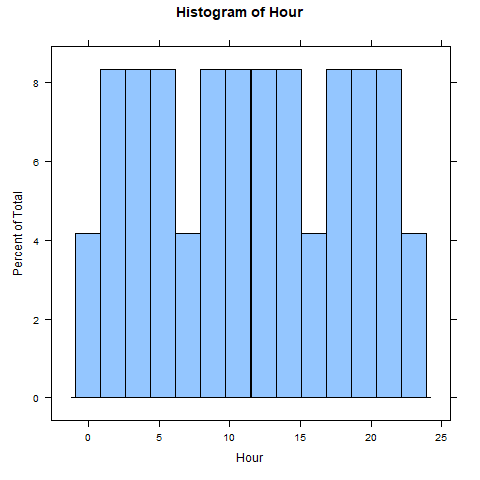

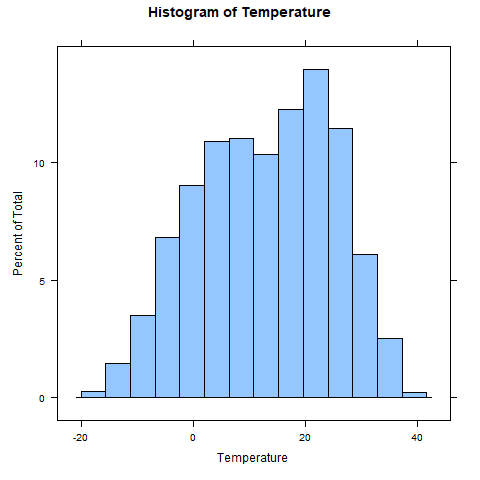

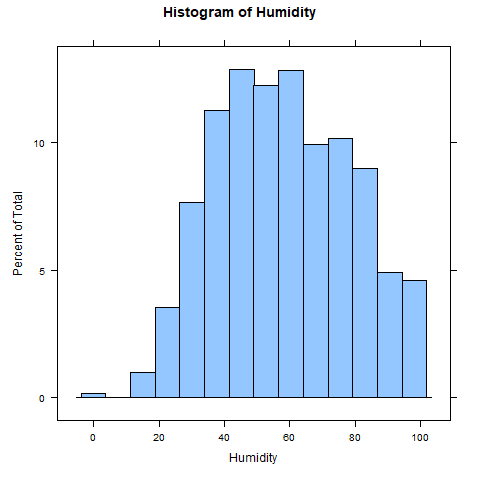

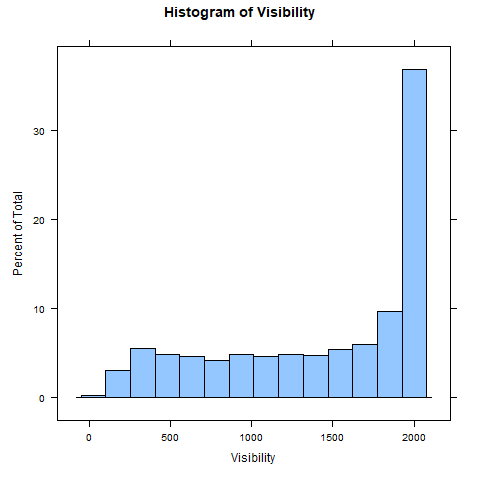

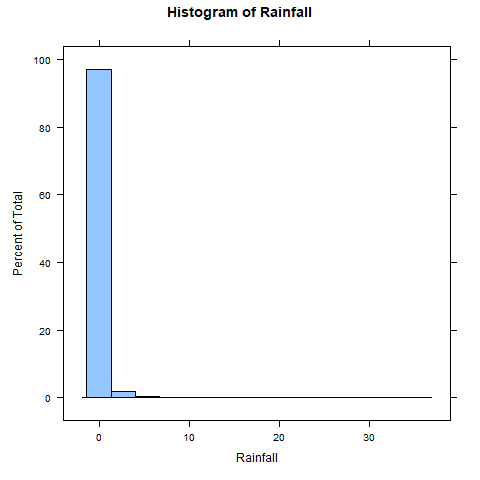

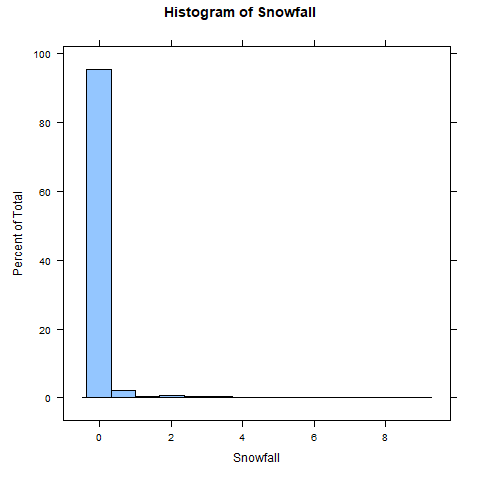

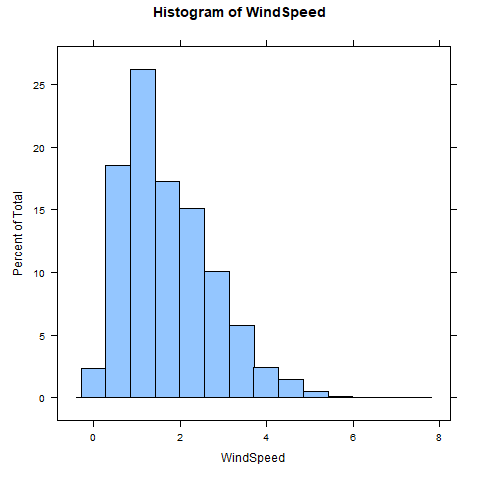

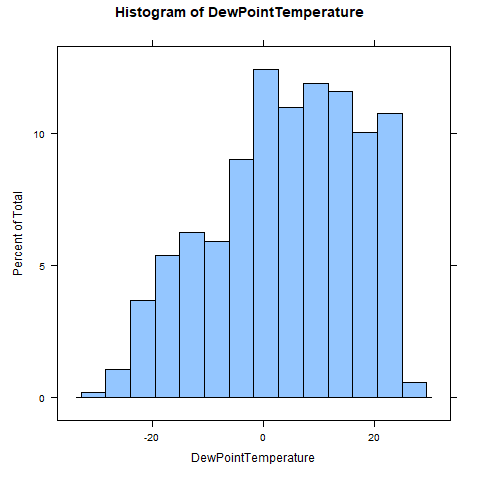

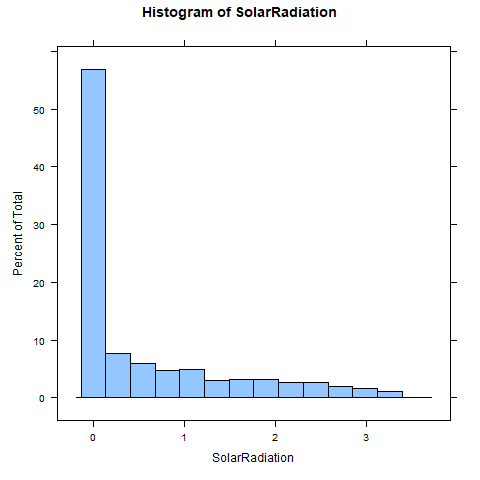

In [77]:
%%R 
print(histogram(dfMedidas$Hour, main = "Histogram of Hour", xlab = "Hour"))
print(histogram(dfMedidas$Temperature, main = "Histogram of Temperature", xlab = "Temperature"))
print(histogram(dfMedidas$Humidity, main = "Histogram of Humidity", xlab = "Humidity"))
print(histogram(dfMedidas$Visibility, main = "Histogram of Visibility", xlab = "Visibility"))
print(histogram(dfMedidas$Rainfall, main = "Histogram of Rainfall", xlab = "Rainfall"))
print(histogram(dfMedidas$Snowfall, main = "Histogram of Snowfall", xlab = "Snowfall"))
print(histogram(dfMedidas$Wind_speed, main = "Histogram of WindSpeed", xlab = "WindSpeed"))
print(histogram(dfMedidas$Dew_point_temperature, main = "Histogram of DewPointTemperature", xlab = "DewPointTemperature"))
print(histogram(dfMedidas$Solar_Radiation, main = "Histogram of SolarRadiation", xlab = "SolarRadiation"))


Podemos ver que la mayoría de variables siguen una distribución normal, y podemos destacar la siguiente información:

* El uso de las bicicletas a lo largo del día sigue un patrón, no una distribución normal.
* Los datos muestran que no hay una gran cantidad de lluvia, nieve o radiación solar.
* La visibilidad es alta.
* Humedad alta.
* Temperatura media alta.

Evaluamos también la presencia de outliers con los diagramas de caja.

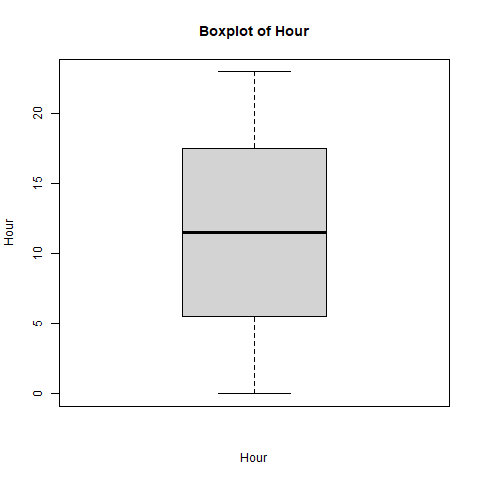

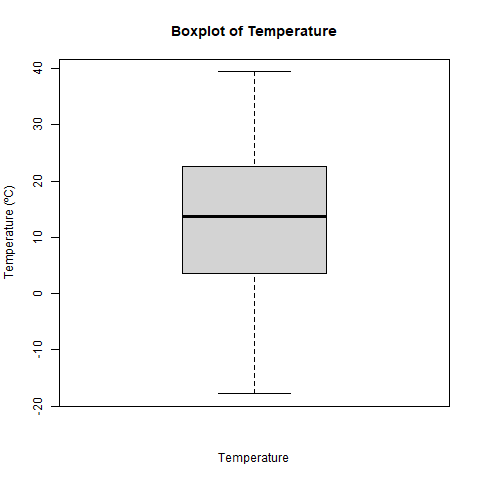

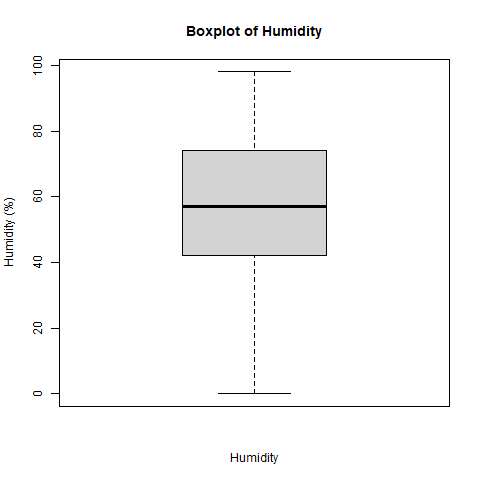

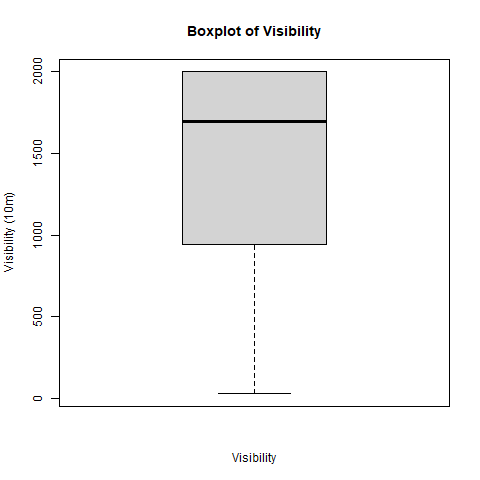

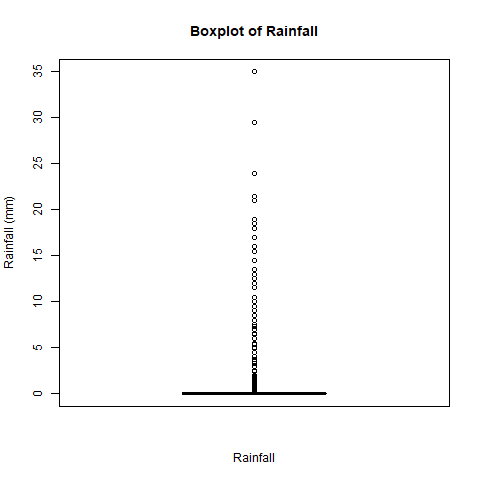

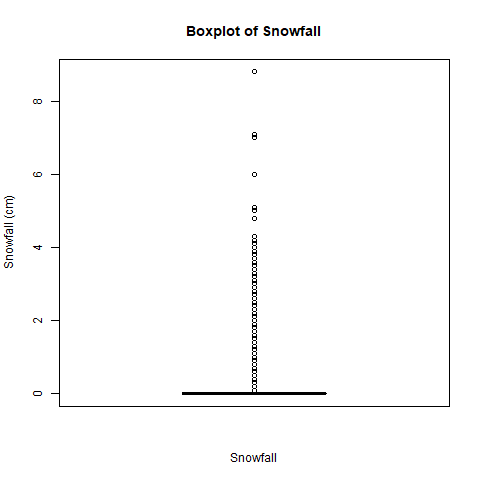

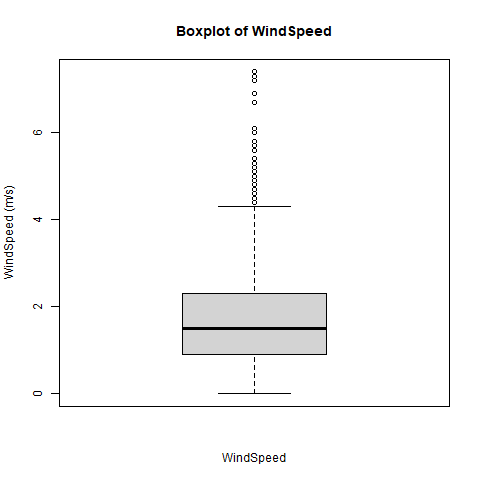

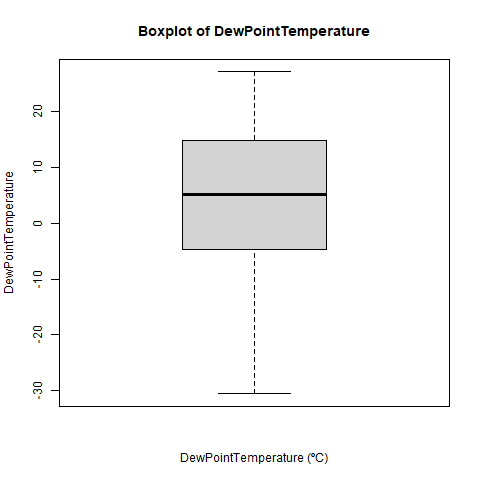

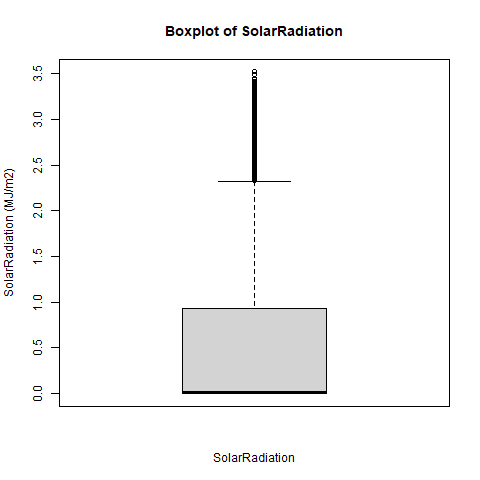

In [78]:
%%R
boxplot(dfMedidas$Hour, main = "Boxplot of Hour", xlab = "Hour", ylab = "Hour")
boxplot(dfMedidas$Temperature, main = "Boxplot of Temperature", xlab = "Temperature", ylab = "Temperature (ºC)")
boxplot(dfMedidas$Humidity, main = "Boxplot of Humidity", xlab = "Humidity", ylab = "Humidity (%)")
boxplot(dfMedidas$Visibility, main = "Boxplot of Visibility", xlab = "Visibility", ylab = "Visibility (10m)")
boxplot(dfMedidas$Rainfall, main = "Boxplot of Rainfall", xlab = "Rainfall", ylab = "Rainfall (mm)")
boxplot(dfMedidas$Snowfall, main = "Boxplot of Snowfall", xlab = "Snowfall", ylab = "Snowfall (cm)")
boxplot(dfMedidas$Wind_speed, main = "Boxplot of WindSpeed", xlab = "WindSpeed", ylab = "WindSpeed (m/s)")
boxplot(dfMedidas$Dew_point_temperature, main = "Boxplot of DewPointTemperature", xlab = "DewPointTemperature (ºC)", ylab = "DewPointTemperature")
boxplot(dfMedidas$Solar_Radiation, main = "Boxplot of SolarRadiation", xlab = "SolarRadiation", ylab = "SolarRadiation (MJ/m2)")

Podemos ver que hay una mayor concentración de Outliers en las variables Rainfall, Snowfall, Windspeed y SolarRadiation, por ello, y para buscar alguna explicación, observaremos el impacto de las estaciones del año en estas variables y en la objetivo.

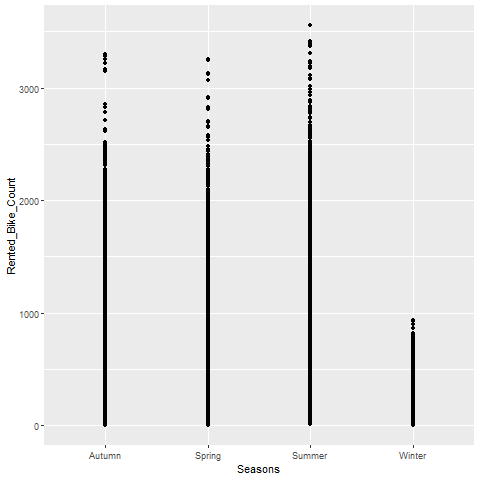

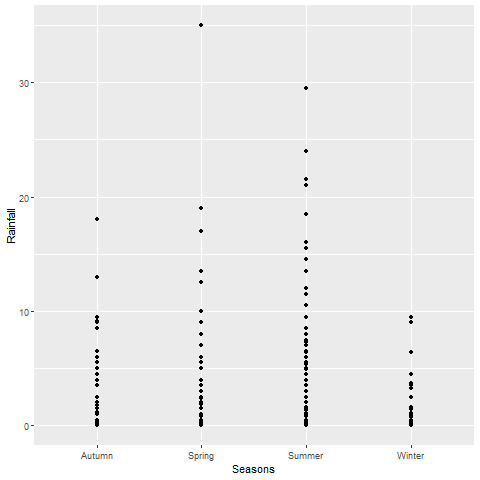

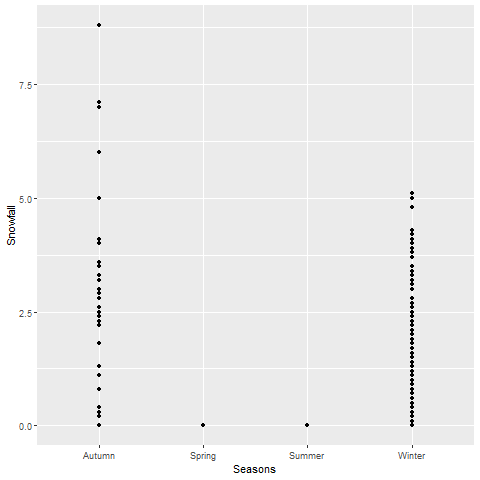

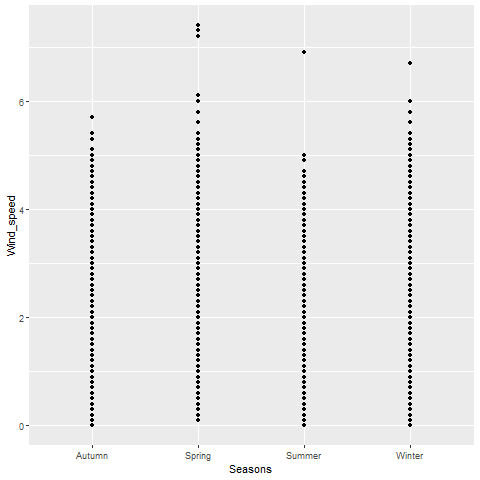

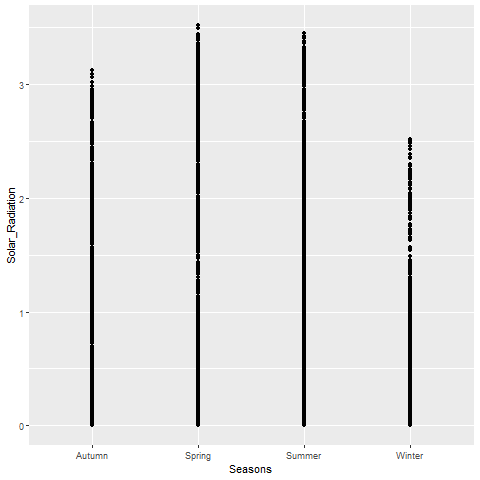

In [79]:
%%R

print(ggplot(dfMedidas, aes(x = Seasons, y = Rented_Bike_Count)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Rainfall)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Snowfall)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Wind_speed)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Solar_Radiation)) + geom_point())

De estas gráficas podemos sacar las siguientes conclusiones:

* Los valores más altos de lluvia se dan en verano y en primavera, dos de las estaciones con mayor uso de las bicicletas, por lo que la presencia de outliers de lluvia es estadísticamente normal.
* Los valores más altos de nieve se dan en otoño y invierno, y aunque en invierno no se usan mucho las bicicletas, en otoño sí, por lo que se da el mismo caso que con la lluvia.
* Los valores más altos de viento se dan en primavera y verano, dándose la misma situación que en los dos casos anteriores.
* Los valores más altos de radiación solar se dan también en primavera y verano, dándose la misma situación que en los dos casos anteriores.

Por todo esto, se puede ver que estos valores que en un principio pueden parecer atípicos, muestran la correlación entre las estaciones y las condiciones meteorológicas.

Haciendo uso de la distancia Cook, veremos si estos outliers son puntos de apalancamiento (tienen mucha influencia)

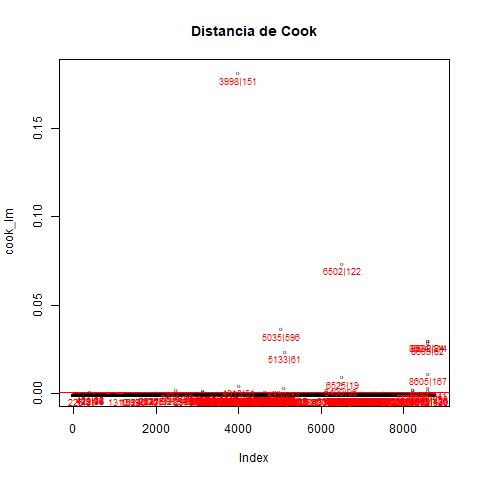

In [80]:
%%R

fit_lm <- lm(Rented_Bike_Count ~ Rainfall + Snowfall + Wind_speed + Solar_Radiation, data = dfMedidas)
cook_lm <- cooks.distance(fit_lm)

plot(cook_lm, pch = "o", cex = 0.5, main = "Distancia de Cook")
abline(h = 4*mean(cook_lm), col = "red")  # línea de corte
text(x = 1 : length(cook_lm) + 1, y = cook_lm - 0.005, cex = 0.75,
     labels = ifelse(cook_lm > 4 * mean(cook_lm), paste0(names(cook_lm),"|",round(dfMedidas$Rented_Bike_Count[as.numeric(names(cook_lm))],0)), ""), col="red")


In [81]:
%%R
influentes <- which(cook_lm > 4*mean(cook_lm))

dfMedidas[order(cook_lm, decreasing = TRUE)[1:10], c("Rented_Bike_Count", "Rainfall", "Snowfall", "Wind_speed", "Solar_Radiation")]

     Rented_Bike_Count Rainfall Snowfall Wind_speed Solar_Radiation
3998               151     35.0      0.0        2.4            0.06
6502               122     29.5      0.0        2.1            0.00
5035               596     21.5      0.0        0.7            0.14
8602                24      9.1      7.1        3.0            0.00
8604               114      0.0      8.8        2.3            0.07
8603                62      0.0      8.8        1.8            0.00
5133                61     24.0      0.0        0.1            0.04
8605               167      1.8      7.0        1.9            0.40
6525                19     21.0      0.0        0.6            0.00
6499                96     18.5      0.0        0.8            0.01


Estos son los valores que más influyen, como podemos ver se tratan de outliers de la variable rainfall y snowfall.

Con esto podemos ver que estos outliers son importantes, más adelante decidiremos si se eliminan o no.

## Análisis de Correlación:

### Correlación entre variables numéricas

In [82]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
num_vars <- num_vars[, !names(num_vars) %in% c("Rented_Bike_Count")]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


                       Hour Temperature Humidity Wind_speed Visibility
Hour                   1.00        0.12    -0.24       0.29       0.10
Temperature            0.12        1.00     0.16      -0.04       0.03
Humidity              -0.24        0.16     1.00      -0.34      -0.54
Wind_speed             0.29       -0.04    -0.34       1.00       0.17
Visibility             0.10        0.03

    -0.54       0.17       1.00
Dew_point_temperature  0.00        0.91     0.54      -0.18      -0.18
Solar_Radiation        0.15        0.35    -0.46       0.33       0.15
Rainfall               0.01        0.05     0.24      -0.02      -0.17
Snowfall              -0.02       -0.22     0.11       0.00      -0.12
                      Dew_point_temperature Solar_Radiation Rainfall Snowfall
Hour                                   0.00            0.15     0.01    -0.02
Temperature                            0.91            0.35     0.05    -0.22
Humidity                               0.54           -0.46     0.24     0.11
Wind_speed                            -0.18            0.33    -0.02     0.00
Visibility                            -0.18            0.15    -0.17    -0.12
Dew_point_temperature                  1.00            0.09     0.13    -0.15
Solar_Radiation                        0.09            1.00    -0.07    -0.07
Rainfall                               0.13           -0.07 

Y de una forma más visual:

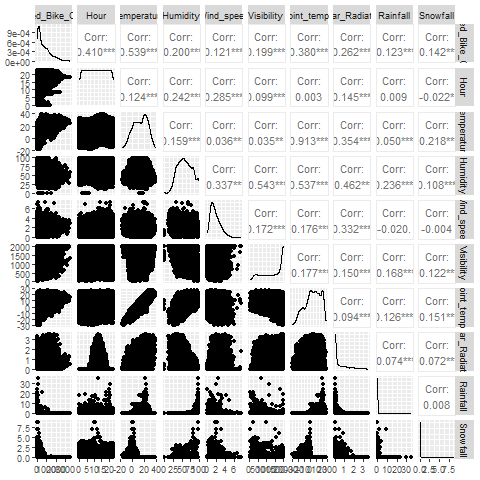

In [83]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars, size = 3)

R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x0000018BA4487100>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x0000018BA4486DC0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x0000018BADBF4DC0>


In addition: Warning messages:
1: In text.default(pos.xlabel[, 1], pos.xlabel[, 2], newcolnames, srt = tl.srt,  :
 2: In text.default(pos.ylabel[, 1], pos.ylabel[, 2], newrownames, col = tl.col,  :
 3: In title(title, ...) :

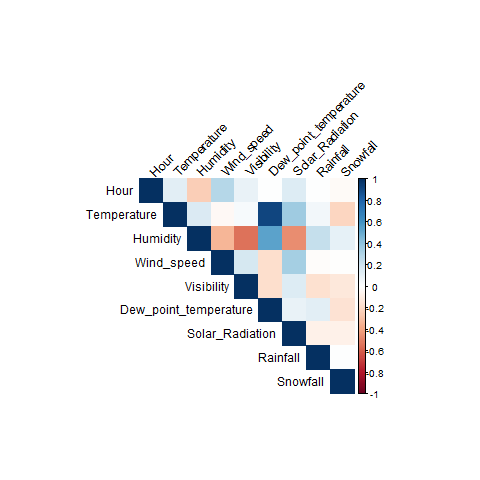

In [84]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45,
        size = 10)

Podemos ver que las variables más relacionadas son la temperatura con la temperatura del punto de rocío (91%), humedad con visibilidad (-54%) y humedad con la temperatura del punto de rocío (54%). 

Estas relaciones tienen sentido, ya que, la temperatura del punto de rocío depende directamente con la temperatura ambiental, por otro lado, una mayor humedad puede derivar en una menor visibilidad por factores como la condensación (niebla, bruma, bochorno, ...), por último, la temperatura del punto de rocío se relaciona tanto con la humedad debido a que la humedad mide el vapor de agua ambiental, mientras que el punto de rocío mide la temperatura a partir de la cual esa humedad ambiental alcance el 100%.

Como se alcanza más de un 90% de correlación entre 2 variables, se ha decidido agrupar dichas variables en una PCA.

In [85]:
%%R
vars <- dfMedidas[, c("Temperature", "Dew_point_temperature")]
vars_scaled <- scale(vars)

pca <- prcomp(vars_scaled, center = TRUE, scale. = TRUE)
print(summary(pca))

dfMedidas$temperature_index <- pca$x[, 1]
dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("Temperature", "Dew_point_temperature")]


Importance of components:
                          PC1    PC2
Standard deviation     1.3830 0.2953
Proportion of Variance 0.9564 0.0436
Cumulative Proportion  0.9564 1.0000


Podemos ver que esta nueva variable explica el 95.6% de la varianza de las variables originales

### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [86]:
%%R
library(ggplot2)

target <- "Rented_Bike_Count"

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)


                           Variable Correlation
temperature_index temperature_index   0.4695230
Hour                           Hour   0.4102573
Solar_Radiation     Solar_Radiation   0.2618370
Humidity                   Humidity  -0.1997802
Visibility               Visibility   0.1992803
Snowfall                   Snowfall  -0.1418036
Rainfall                   Rainfall  -0.1230740
Wind_speed               Wind_speed   0.1211084


Como podemos ver la variable más relacionada con la objetivo es el índice de la temperatura (47% de correlación), es decir, cuanto mayor es la temperatura mayor es el uso de las biciletas, esto responde al comportamiento promedio del usuario de bicicletas.
Por otro lado, el resto de valores no son significativos.

## Selección de Atributos:

Analizaremos la importancia de los atributos mediante filtro, ranking y embedido, para, de esta forma, poder evaluar la posibilidad de eliminar algún atributo más.

### Selección por Filtrado

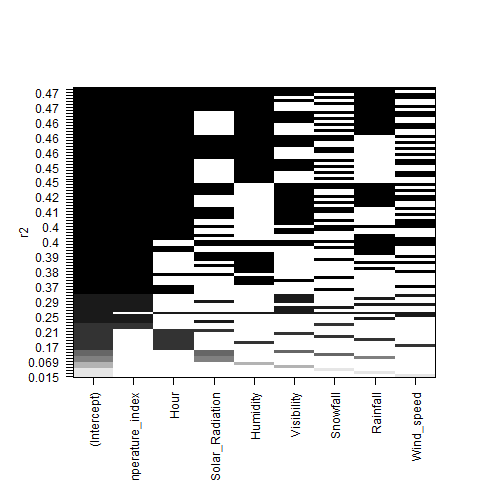

In [87]:
%%R
fit_leaps <- regsubsets(Rented_Bike_Count ~ temperature_index + Hour + Solar_Radiation + Humidity + Visibility + Snowfall + Rainfall + Wind_speed, data = dfMedidas, nbest = 16)

plot(fit_leaps, scale = "r2")

In [88]:
%%R
fit_lm <- lm(Rented_Bike_Count ~ temperature_index + Hour + Solar_Radiation + Humidity + Visibility + Snowfall + Rainfall + Wind_speed, data = dfMedidas)
calc.relimp(fit_lm)

Response variable: Rented_Bike_Count 
Total response variance: 416021.7 
Analysis based on 8760 observations 

8 Regressors: 
temperature_index Hour Solar_Radiation Humidity Visibility Snowfall Rainfall Wind_speed 
Proportion of variance explained by model: 47.02%
Metrics are not normalized (rela=FALSE). 

Relative importance metrics: 

                          lmg
temperature_index 0.230726777
Hour              0.121804636
Solar_Radiation   0.028961875
Humidity          0.043888414
Visibility        0.018643016
Snowfall          0.008292865
Rainfall          0.012313705
Wind_speed        0.005575394

Average coefficients for different model sizes: 

                            1X         2Xs          3Xs          4Xs
temperature_index  218.9678335  227.497005  237.0036751  247.1392111
Hour                38.2248886   36.845922   35.5973487   34.3737256
Solar_Radiation    194.3999115  167.418775  136.1206696  100.7333056
Humidity            -6.3282137   -5.900150   -5.8680954   -6.234

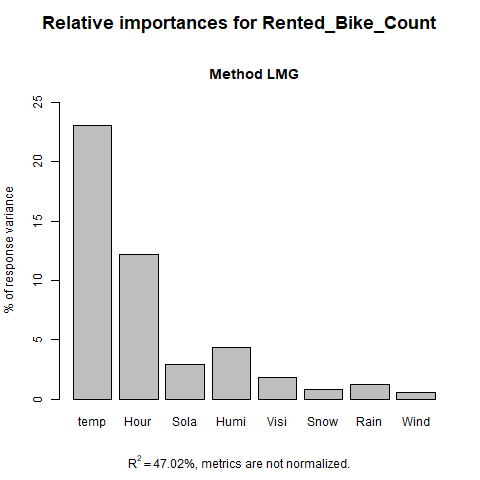

In [89]:
%%R
plot(calc.relimp(fit_lm) )

Podemos ver que hay 2 atributos con una clara importancia (> 10% de la varianza), por otro lado, los que menos importantes serían windspeed y rainfall. Evaluaremos otros métodos antes de considerar eliminar alguno de estos aptributos.

### Selección por Ranking

Boruta performed 10 iterations in 1.004403 mins.
 8 attributes confirmed important: Hour, Humidity, Rainfall, Snowfall,
Solar_Radiation and 3 more;
 No attributes deemed unimportant.
                    meanImp medianImp    minImp    maxImp normHits  decision
Wind_speed         25.94859  25.74608  24.35331  27.73379        1 Confirmed
Rainfall           49.01373  48.53136  47.61921  51.69303        1 Confirmed
Snowfall           16.87584  16.74713  16.38096  17.67716        1 Confirmed
Visibility         41.82881  41.79454  40.59674  43.68068        1 Confirmed
Humidity           57.70307  57.74234  52.57434  61.25096        1 Confirmed
Solar_Radiation    43.09352  43.01689  41.88985  44.21448        1 Confirmed
Hour              117.40765 116.88022 109.28166 125.01300        1 Confirmed
temperature_index 155.65658 156.76326 144.39408 161.31109        1 Confirmed


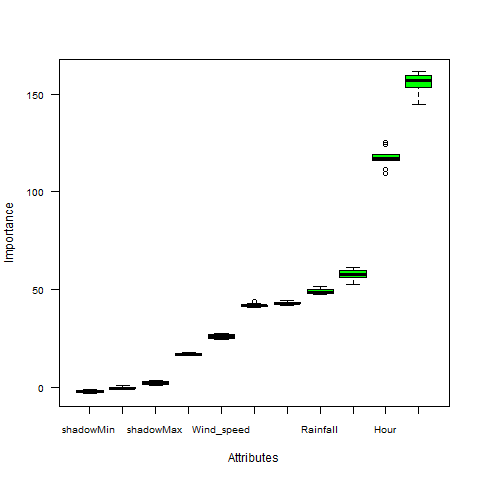

In [90]:
%%R
formula <- to_formula( c("temperature_index", "Hour", "Solar_Radiation", "Humidity", 
                        "Visibility", "Snowfall", "Rainfall", "Wind_speed"), "Rented_Bike_Count")

out.boruta <- Boruta(formula, data = dfMedidas)
plot(out.boruta, cex.axis = 0.8, las=1)
print(out.boruta)
attStats(out.boruta)

Podemos ver que el atributo más importante es temperature_index seguido de Hour, el resto están muy alehados de estos valores, sin embargo, el algoritmo los marca todos como importantes.

### Seleccion por Embedido

Como criterio de embedido usaremos random forest, serán más importantes aquellos atributos usados en los árboles con menor error

In [91]:
%%R
modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,
                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)

rf_imp <- importance(modelo.rf, importance.type = 1)
print(rf_imp)

                    %IncMSE IncNodePurity
temperature_index 177.76419    1026677619
Hour              144.48220     930625895
Solar_Radiation    60.71498     366012828
Humidity           83.78667     356414867
Visibility         67.94635     196063185
Snowfall           25.92617      38469152
Rainfall           72.78365     115250569
Wind_speed         44.08800     152687502


De nuevo, podemos ver que las variables más importantes son temperature_index y Hour, además, podemos ver que las variables con un valor cercano o menor que 30, como Snowfall o Wind_Speed, son muy poco relevantes. Sin embargo, no podemos eliminar ninguna variable.

## Reducción de Dimensionalidad:

Aunque ya hemos realizado un estudio sobre la correlación de los atributos, ahora analizaremos más detalladamente si se puede o no considerar reducir la dimensionalidad del problema fusionando algunos más.

In [92]:
%%R
atributos <- c("temperature_index", "Hour", "Solar_Radiation", "Humidity", 
               "Visibility", "Snowfall", "Rainfall", "Wind_speed")

res.pca <- prcomp(dfMedidas[,atributos], scale = TRUE)
summary(res.pca)

Importance of components:
                          PC1    PC2    PC3    PC4    PC5     PC6    PC7
Standard deviation     1.4988 1.1673 1.0651 0.9561 0.9122 0.85515 0.7720
Proportion of Variance 0.2808 0.1703 0.1418 0.1143 0.1040 0.09141 0.0745
Cumulative Proportion  0.2808 0.4511 0.5929 0.7072 0.8112 0.90263 0.9771
                           PC8
Standard deviation     0.42769
Proportion of Variance 0.02286
Cumulative Proportion  1.00000


Como podemos ver, a partir de 5 PCAs la varianza explicada es buena (>80%), sin embargo, se puede considerar que el mejor resultado es de 6 (~90%), ya que reduce la dimensionalidad sin perder apenas explicación.

In [97]:
%%R
pca_features <- as.data.frame(res.pca$x[, 1:5])
colnames(pca_features) <- paste0("PC", 1:5)
dfMedidas <- cbind(dfMedidas, pca_features)

dfMedidas <- dfMedidas[, !names(dfMedidas) %in% c("Hour", "Humidity", "Wind_speed", "Visibility", "Solar_Radiation",
               "Rainfall", "Snowfall", "temperature_index")]

In [98]:
%%R
head(dfMedidas)

  Rented_Bike_Count Seasons Holiday Functioning Day        PC1       PC2
1               254  Winter       0               1 -0.7332683 -2.062389
2               204  Winter       0               1 -0.2015324 -2.175319
3               173  Winter       0               1 -0.2945258 -2.127447
4               107  Winter       0               1 -0.2678435 -2.096548
5                78  Winter       0               1 -0.9726329 -1.968856
6               100  Winter       0               1 -0.6756575 -2.024013
        PC3       PC4       PC5      PC1.1     PC2.1     PC3.1     PC4.1
1 0.7788506 0.6870143 1.2434042 -0.7332683 -2.062389 0.7788506 0.6870143
2 1.2975470 0.6928921 1.0023137 -0.2015324 -2.175319 1.2975470 0.6928921
3 1.1443520 0.7290576 0.9126162 -0.2945258 -2.127447 1.1443520 0.7290576
4 1.1204707 0.7546967 0.7927381 -0.2678435 -2.096548 1.1204707 0.7546967
5 0.4837322 0.8300959 0.8496979 -0.9726329 -1.968856 0.4837322 0.8300959
6 0.7498297 0.8482615 0.6657240 -0.6756575 -2.02401

Ahora, hemos eliminado los atributos anteriores y los hemos sustituido por las PCAs seleccionadas previamente, reduciendo la dimensionalidad del problema.

Dado que se trata de un problema de regresión, no se puede aplicar LDA, pues su objetivo es separar las clases.

Antes de empezar con los modelos, transformamos las variables categoricas a numéricas:

In [95]:
%%R
dfMedidas$Holiday <- ifelse(dfMedidas$Holiday == "Holiday", 1, 0)
dfMedidas$`Functioning Day` <- ifelse(dfMedidas$`Functioning Day` == "Yes", 1, 0)

In [103]:
%%R
dfMedidas$Seasons <- factor(dfMedidas$Seasons,
                     levels = c("Winter", "Spring", "Summer", "Autumn"))

dummies_seasons <- model.matrix(~ Seasons - 1, data = dfMedidas)

dfMedidas <- cbind(dfMedidas, dummies_seasons)
dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("Seasons")]


In [104]:
%%R
head(dfMedidas)

  Rented_Bike_Count Holiday Functioning Day        PC1       PC2       PC3
1               254       0               1 -0.7332683 -2.062389 0.7788506
2               204       0               1 -0.2015324 -2.175319 1.2975470
3               173       0               1 -0.2945258 -2.127447 1.1443520
4               107       0               1 -0.2678435 -2.096548 1.1204707
5                78       0               1 -0.9726329 -1.968856 0.4837322
6               100       0               1 -0.6756575 -2.024013 0.7498297
        PC4       PC5      PC1.1     PC2.1     PC3.1     PC4.1     PC5.1
1 0.6870143 1.2434042 -0.7332683 -2.062389 0.7788506 0.6870143 1.2434042
2 0.6928921 1.0023137 -0.2015324 -2.175319 1.2975470 0.6928921 1.0023137
3 0.7290576 0.9126162 -0.2945258 -2.127447 1.1443520 0.7290576 0.9126162
4 0.7546967 0.7927381 -0.2678435 -2.096548 1.1204707 0.7546967 0.7927381
5 0.8300959 0.8496979 -0.9726329 -1.968856 0.4837322 0.8300959 0.8496979
6 0.8482615 0.6657240 -0.6756575 -2.0

# Modelos

## Regresión Lineal

In [105]:
%%R
fit_lm <- lm(Rented_Bike_Count ~ ., data = dfMedidas)
summary(fit_lm)


Call:
lm(formula = Rented_Bike_Count ~ ., data = dfMedidas)

Residuals:
     Min       1Q   Median       3Q      Max 
-1236.93  -302.98   -67.04   216.95  2591.57 

Coefficients: (6 not defined because of singularities)
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)         12.609     26.836   0.470 0.638470    
Holiday            -88.034     22.745  -3.870 0.000109 ***
`Functioning Day`  914.796     28.047  32.617  < 2e-16 ***
PC1               -152.378      3.355 -45.424  < 2e-16 ***
PC2                110.872      6.467  17.145  < 2e-16 ***
PC3                -22.752      5.002  -4.549 5.47e-06 ***
PC4                -21.163      5.336  -3.966 7.36e-05 ***
PC5               -190.137      5.362 -35.461  < 2e-16 ***
PC1.1                   NA         NA      NA       NA    
PC2.1                   NA         NA      NA       NA    
PC3.1                   NA         NA      NA       NA    
PC4.1                   NA         NA      NA       NA    
PC5.1       

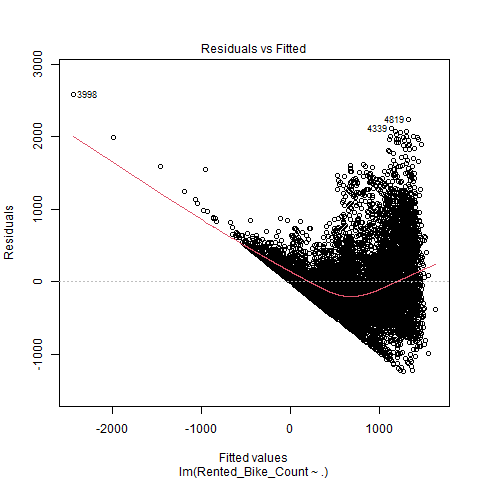

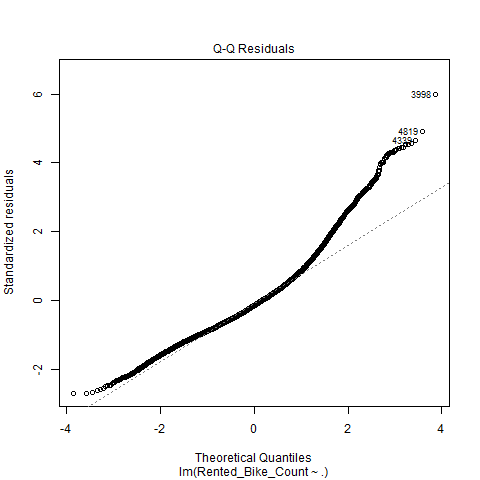

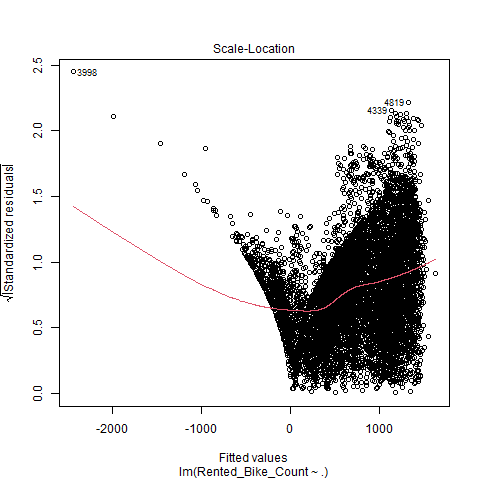

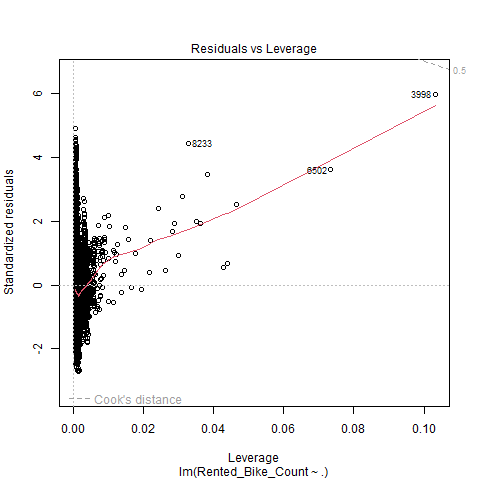

In [106]:
%%R
plot(fit_lm)